In [1]:
import numpy as np
from pathlib import Path

# path to the data file
data_path = Path.home() / "Downloads" / "Project2_set4.txt"

# load photon energies
E = np.loadtxt(data_path)

# count the photons
N = len(E)

print(f"File: {data_path}")
print(f"N = {N} photons")
print(f"Min energy = {E.min():.4f} a.u.")
print(f"Max energy = {E.max():.4f} a.u.")
print(f"Mean energy = {E.mean():.4f} a.u.")
print("First 5 values:", E[:5])

File: /Users/luisrojascastillo/Downloads/Project2_set4.txt
N = 473 photons
Min energy = 0.3702 a.u.
Max energy = 2065.1403 a.u.
Mean energy = 148.4721 a.u.
First 5 values: [141.37264824 227.05592641 223.67281882 227.80366888 187.19314755]


From here, I found that there are 473 photons.

$N$ is a fixed, known number. That must mean that $n_s$ and $n_b$ are not two separate free parameters, because they have to satisfy

$N = n_s + n_B = 473 \Rightarrow n_b = 473 - n_s$ 

So the data only let me fit one number for how much signal there is.

The probability density for a single photon is then a mix of the signal and background shapes:

$f(E | E_0, \Gamma, n_s) = \frac{n_s}{N} \frac{1}{\pi \Gamma \left[1 + \left(\frac{E - E_o}{\Gamma}\right)^2 \right]} + \frac{N - n_s}{N} \frac{1}{E_b} e^{-E/E_b}, \quad E_b = 100 \text{ a.u.}$

The ordinary (not extended) negative log-likelihood is

$-\ln L (E_o, \Gamma, n_s) = -\sum_{i=1}^{473} \ln f (E_i | E_o, \Gamma, n_s)$

There are three parameters here, and the background count $n_b$ follows from $n_b = 473 - n_s$

For the likelihood function, 

Since I found that there are $N = 473$ measured photon energies $\{E_1, E_2, \dots, E_N \}$. The energies are measured with high precision, so the meaasurement uncertainty isn't important.

**Signal (Wigner / Lorentzian / Cauchy) pdf**, with unknown $E_o$ and $\Gamma$:

$ f_s (E \mid E_o, \Gamma) = \frac{1}{\pi \Gamma \left[1 + \left( \dfrac{E - E_o}{\Gamma} \right)^ 2 \right]}$

For the background (exponential) pdf, with known $E_b = 100$ a.u. :

$f_B(E) = \frac{1}{E_b} \, e^{-E/E_b}$ 

Since the total number of photons is known: $N = n_s + n_b$, so $n_B = N - n_s$. Only $n_s$ is a free parameter, so this is an ordinary likelihood. Each photon is signal with probability $n_s/N$ and background with probability $(N - n_s)/N$

Now, the probability density for a single photon is

$ f(E \mid E_o, \Gamma, n_s) = \frac{n_s}{N} \, f_s(E \mid E_o, \Gamma) + \frac{N - n_s}{N} \, f_B(E)$


For the likelihood, since the photons are independent, the likelihood is a product over all of them, which is

$L(E_o, \Gamma, n_s) = \prod_{i=1}^{N} \left[ \frac{n_s}{N} \, \frac{1}{\pi \Gamma \left[1 + \left( \dfrac{E_i - E_o}{\Gamma} \right)^2 \right]} + \frac{N - n_s}{N} \, \frac{1}{E_b} \, e^{-E_i/E_b} \right]$

For the negative log-likelihood

$-\ln L(E_o, \Gamma, n_s) = -\sum_{i=1}^{N} \ln \left[ \frac{n_s}{N} \, \frac{1}{\pi \Gamma \left[1 + \left( \dfrac{E_i - E_o}{\Gamma} \right)^2 \right]} + \frac{N - n_s}{N} \, \frac{1}{E_b} \, e^{-E_i/E_b} \right]$

The free parameters are $E_o$, $\Gamma$, and $n_s$, with $0 \le n_s \le N$ and $\Gamma > 0$.
Fixed: $N = 473$ and $E_b = 100$ a.u.
Derived after the fit: $n_B = N - \hat{n}_s$

For the normalization, the $f_s$ function is normalized on $(-\infty, \infty)$, and $f_B$ on $[0, \infty)$. Since $E_o \approx 200$ a.u. is many widths $\Gamma$ abvoe zero, the part of the Lorentzian below $E = 0$ is negligible. Both pdfs then integrate to about 1 over the physical range $E \ge 0$, and so does the mixture.

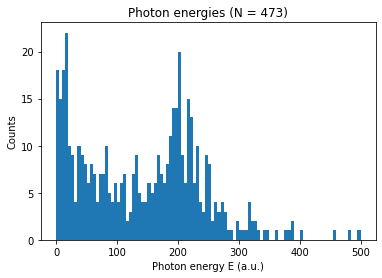

In [2]:
import matplotlib.pyplot as plt

plt.hist(E, bins=100, range=(0,500))
plt.xlabel("Photon energy E (a.u.)")
plt.ylabel("Counts")
plt.title(f"Photon energies (N = {N})")
plt.show()

In [3]:
E_b = 100.0

def nll(params):
    E0, Gamma, ns = params
    fs = 1.0 / (np.pi * Gamma * (1.0 + ((E - E0) / Gamma)**2))
    fB = np.exp(-E /E_b) / E_b
    f = (ns / N) * fs + ((N - ns) / N) * fB
    return -np.sum(np.log(f))

print(nll([200, 20, 300])) # E0 = 200, Gamma = 20, ns = 300
print(nll([150, 20, 300])) # E0 = 150, Gamma = 20, ns = 300

2789.943610314377
2916.546368642312


This is the negative log-likelihood function being applied to get the likelihood of how well a choice of E0, $\Gamma$, and $n_s$ describes the data.

This is part 4, which is the histogram of the distribution of photon energies.

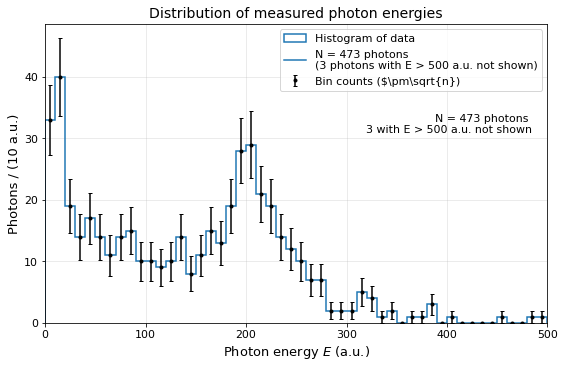

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Binning
E_min, E_max, bin_width = 0, 500, 10
bins = np.arange(E_min, E_max + bin_width, bin_width)

counts, edges = np.histogram(E, bins=bins)
centers = 0.5 * (edges[:-1] + edges[1:])
errors = np.sqrt(counts)
n_over = np.sum(E > E_max)

fig, ax = plt.subplots(figsize=(9,5.5))
ax.hist(E, bins=bins, histtype="step", color="tab:blue", linewidth=1.5, label="Histogram of data")
ax.errorbar(centers, counts, yerr=errors, fmt="o", color="black", markersize=3, capsize=2, label=r"Bin counts ($\pm\sqrt{n})")
ax.text(0.97, 0.70, f"N = {N} photons \n{n_over} with E > {E_max} a.u. not shown", transform=ax.transAxes, ha="right", va="top", fontsize=11)
ax.plot([], [], "", label=f"N = {N} photons \n({n_over} photons with E > {E_max} a.u. not shown)")

ax.set_xlabel("Photon energy $E$ (a.u.)", fontsize=13)
ax.set_ylabel(f"Photons / ({bin_width} a.u.)", fontsize=13)
ax.set_title("Distribution of measured photon energies", fontsize=14)
ax.set_xlim(E_min, E_max)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=11)
plt.show()

The blue line isn't a fit, but the histogram itself, so it's okay that the line goes through every single point on the graph.
For the blue line, each bin is drawn as a flat step at the height of its count. The black dots are the same count, but drawn as a point at the bin center, with a $\sqrt{n}$ error bar.

This is part 5, which was using the maximum likelihood method to get your best estiamte of the values of $n_s$, $n_b$, $E_0$, $\Gamma$ with scipy.optimize.minimize.

In [5]:
from scipy.optimize import minimize

def m2lnL(params):
    # -2ln L: the function that is being minimized
    return 2 * nll(params)

# Initial guesses from the histogram
p0 = [200.0, 25.0, 190.0]

# Bounds: [E0, Gamma, ns]
bounds = [(0.0, 500.0), (1e-3, 200.0), (0.0, N)]

result = minimize(m2lnL, p0, method="L-BFGS-B", bounds=bounds)

E0_hat, Gamma_hat, ns_hat = result.x
nb_hat = N - ns_hat

print("Converged:", result.success, "-", result.message)
print(f"E0 = {E0_hat:.2f} a.u.")
print(f"Gamma = {Gamma_hat:.2f} a.u.")
print(f"ns = {ns_hat:.1f}")
print(f"nb = {nb_hat:.1f} (= N - ns)")
print(f"-2 ln L at minimum = {result.fun:.2f}")

Converged: True - CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
E0 = 206.00 a.u.
Gamma = 21.84 a.u.
ns = 180.2
nb = 292.8 (= N - ns)
-2 ln L at minimum = 5506.40


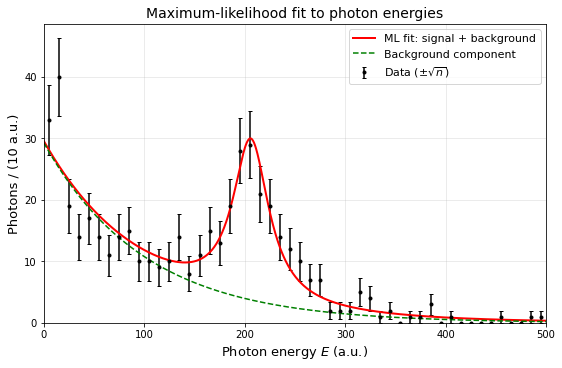

In [6]:
x = np.linspace(E_min, E_max, 1000)
fs_fit = 1.0 / (np.pi * Gamma_hat * (1.0 + ((x - E0_hat) / Gamma_hat)**2))
fB_fit = np.exp(-x/E_b) / E_b

# multiplies the PDf by the bin width turns it into "photons per bin"
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(centers, counts, yerr=errors, fmt="o", color="black", markersize=3, capsize=2, label=r"Data ($\pm\sqrt{n}$)")
ax.plot(x, (ns_hat * fs_fit + nb_hat * fB_fit) * bin_width, "r-", lw=2, label="ML fit: signal + background")
ax.plot(x, nb_hat * fB_fit * bin_width, "g--", lw=1.5, label="Background component")

ax.set_xlabel("Photon energy $E$ (a.u.)", fontsize=13)
ax.set_ylabel(f"Photons / ({bin_width} a.u.)", fontsize=13)
ax.set_title("Maximum-likelihood fit to photon energies", fontsize=14)
ax.set_xlim(E_min, E_max)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(fontsize=11)

The graph up above here is the fit over the data. The first two bins come out over the curve, which is probably because of some normal fluctuations. and everything else falls in line quite nice.

For the scipy.optimize.minimize function, the bounds on every parameter, when using the maximum-likelihood estimates, are

$E_0 \quad \quad 206.0 \text{ a.u.}$ 

$\Gamma \quad \quad 21.8 \text{ a.u.}$ 

$n_s \quad \quad 180.2$ 

$n_b = N - n_s \quad \quad 292.8 $ 

$-2 \ln L \text{ at minimum} \quad \quad 5506.40$

This is for part 6, which is just the histogram of the distribution of photon energies.

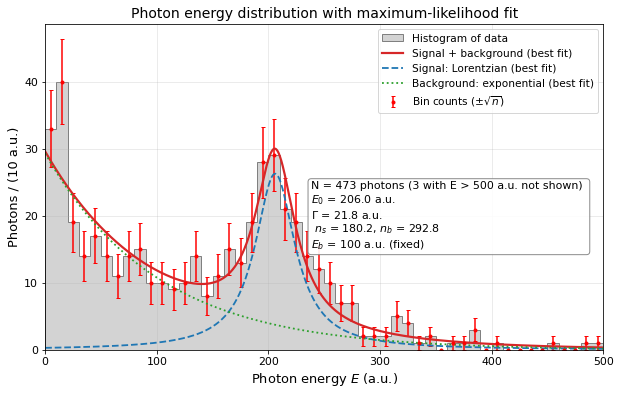

In [7]:
x = np.linspace(E_min, E_max, 2000)

# Best-fit pdfs which each integrate to 1
fs_fit = 1.0 / (np.pi * Gamma_hat * (1.0 + ((x - E0_hat) / Gamma_hat)**2))
fB_fit = np.exp(-x / E_b) / E_b

# (number of photons in the component) * (pdf) * (bin width)
signal = ns_hat * fs_fit * bin_width
background = nb_hat * fB_fit * bin_width
total = signal + background

fig, ax = plt.subplots(figsize=(10,6))

# data
ax.hist(E, bins=bins, histtype="stepfilled", color="lightgray", edgecolor="gray", label="Histogram of data")
ax.errorbar(centers, counts, yerr=errors, fmt="o", color="red", markersize=3, capsize=2, label=r"Bin counts ($\pm\sqrt{n}$)")

ax.plot(x, total, color="tab:red", lw=2.2, label="Signal + background (best fit)")
ax.plot(x, signal, color="tab:blue", lw=1.8, ls="--", label="Signal: Lorentzian (best fit)")
ax.plot(x, background, color="tab:green", lw=1.8, ls=":", label="Background: exponential (best fit)")

info = (f"N = {N} photons ({n_over} with E > {E_max} a.u. not shown) \n" 
        f"$E_0$ = {E0_hat:.1f} a.u. \n"
        f"$\\Gamma$ = {Gamma_hat:.1f} a.u. \n"
        f" $n_s$ = {ns_hat:.1f}, $n_b$ = {nb_hat:.1f}\n"
        f"$E_b$ = {E_b:.0f} a.u. (fixed)")
ax.text(0.97, 0.52, info, transform=ax.transAxes, ha="right", va="top", multialignment="left", fontsize=11, bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))

ax.set_xlabel("Photon energy $E$ (a.u.)", fontsize=13)
ax.set_ylabel(f"Photons / ({bin_width} a.u.)", fontsize=13)
ax.set_title("Photon energy distribution with maximum-likelihood fit", fontsize=14)
ax.set_xlim(E_min, E_max)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=10.5, loc="upper right")

In the graph, the background, signal, and the signal+background, as well as the bin counts, are all on display.

Since a pdf integrates to 1, it can't be directly compared to bin counts. Multiplying by the number of photons in that component and by the bin width converts it to "photons per 10 a.u.":

$ \text{expected counters per bin } \approx n \cdot f(E) \cdot \Delta E$

Now this is for part 7, which is the plot of $-2 \log \mathcal{L} - 2 \log \mathcal{L}_{max}$ map as a function of $E_0$ and $\Gamma$ for the best-fit value of $n_s$ that was found, which is 180.2

1-sigma uncertainties (from the -2 ln L_max + 1 contour, ns fixed):
E0 = 206.00 + 3.02/-2.93 a.u. (symmetric approx: \pm2.97)
Gamma = 21.84 + 2.76 / -2.47 a.u. (symmetric approx: $\pm$2.62)


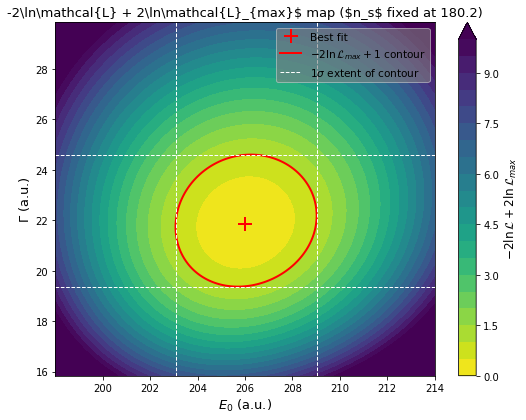

In [8]:
# -2 ln L at its minimum
m2lnL_max = m2lnL([E0_hat, Gamma_hat, ns_hat])

# Grid of E0 and Gamma values around the best fit; ns stays fixed at its best-fit value
E0_grid = np.linspace(E0_hat - 8, E0_hat + 8, 201)
Gamma_grid = np.linspace(Gamma_hat - 6, Gamma_hat + 8, 201)

dm2lnL = np.empty((len(Gamma_grid), len(E0_grid)))
for i, G in enumerate(Gamma_grid):
    for j, e0 in enumerate(E0_grid):
        dm2lnL[i, j] = m2lnL([e0, G, ns_hat]) - m2lnL_max

fig, ax = plt.subplots(figsize=(8.5, 6.5))

# color map of the difference from the minimum
cf = ax.contourf(E0_grid, Gamma_grid, dm2lnL, levels=np.linspace(0, 10, 21), cmap="viridis_r", extend="max")
cbar = fig.colorbar(cf, ax=ax)
cbar.set_label(r"$-2\ln\mathcal{L} + 2\ln\mathcal{L}_{max}$", fontsize=12)

# The -2 ln L_max + 1 contour
cs = ax.contour(E0_grid, Gamma_grid, dm2lnL, levels=[1.0], colors="red", linewidths=2)

# 1-sigma uncertainty = how far the contour reaches along each axis
contour_pts = np.vstack(cs.allsegs[0])
E0_lo, E0_hi = contour_pts[:,0].min(), contour_pts[:,0].max()
G_lo, G_hi = contour_pts[:, 1].min(), contour_pts[:, 1].max()

sE0_minus, sE0_plus = E0_hat - E0_lo, E0_hi - E0_hat
sG_minus, sG_plus = Gamma_hat - G_lo, G_hi - Gamma_hat

ax.plot(E0_hat, Gamma_hat, "r+", markersize=14, markeredgewidth=2, label="Best fit")
for v in (E0_lo, E0_hi):
    ax.axvline(v, color="white", ls="--", lw=1)
for h in (G_lo, G_hi):
    ax.axhline(h, color="white", ls="--", lw=1)
ax.plot([], [], color="red", lw=2, label=r"$-2\ln\mathcal{L}_{max} + 1$ contour")
ax.plot([], [], color="white", ls="--", lw=1, label=r"$1\sigma$ extent of contour")

ax.set_xlabel(r"$E_0$ (a.u.)", fontsize=13)
ax.set_ylabel(r"$\Gamma$ (a.u.)", fontsize=13)
ax.set_title(rf"-2\ln\mathcal{{L}} + 2\ln\mathcal{{L}}_{{max}}$ map ($n_s$ fixed at {ns_hat:.1f})", fontsize=13)
ax.legend(fontsize=10.5, loc="upper right", facecolor="gray", framealpha=0.6)

print("1-sigma uncertainties (from the -2 ln L_max + 1 contour, ns fixed):")
print(f"E0 = {E0_hat:.2f} + {sE0_plus:.2f}/-{sE0_minus:.2f} a.u. (symmetric approx: \pm{(sE0_plus + sE0_minus)/2:.2f})")
print(f"Gamma = {Gamma_hat:.2f} + {sG_plus:.2f} / -{sG_minus:.2f} a.u. (symmetric approx: $\pm${(sG_plus + sG_minus)/2:.2f})")

The $n_s$ fixed at its best-fit value of 180.2, the 1$\sigma$ uncertainties are:

For the parameter $E_0$, the best fit is 206.00 a.u., and the 1$\sigma$ uncertainity is $+3.02/-2.93$ a.u. ($\approx \pm 3.0$)

For the parameter $\Gamma$, the best fit is 21.84 a.u., and the $1\sigma$ uncertainty is $-2.76/-2.47$ a.u. ($\approx \pm 2.6$)

The map shows that each point is how much worse the fit is than the best fit, $\Delta = -2 \ln L - (-2 \ln L_{max})$. It's 0 at the best fit, and grows as you move away.

The contour is at $+1$ because since we're minimizing $-2 \ln L$, the $1\sigma$ boundary is where the $\Delta = 1$ (for $-\ln L$, it would be 0.5). This is the reason why the factor of 2 from part 4.

These uncertainties assume that $n_s$ is fixed at exactly 180.2. However, in reality, $n_s$ also has its own uncertainity, and allowing it to vary would make the $E_0$ and $\Gamma$ errors a little larger, mainly for $\Gamma$, becuase width and signal yield are correlated. 

This is for part 8, which I understand is for graduate students, but I wanted to see if I could do it

/var/folders/lc/khdfnsgs41db7k05py3cybq80000gn/T/ipykernel_88608/3777183392.py:21: RuntimeWarning: divide by zero encountered in log
  return -2.0 * np.sum(np.log(np.maximum(f, 1e-3000)))
/Users/luisrojascastillo/opt/anaconda3/lib/python3.9/site-packages/scipy/optimize/_numdiff.py:590: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0


ns_true  mean E0_hat  sigma(E0_hat)             bias
     25        341.2          276.1    +135.2 $\pm$ 12.3
     50        257.6          185.6     +51.6 $\pm$  8.3
     75        203.4          116.8      -2.6 $\pm$  5.2
    100        204.3           87.8      -1.7 $\pm$  3.9
    150        202.0           64.9      -4.0 $\pm$  2.9
    200        200.8           50.3      -5.2 $\pm$  2.3
    250        200.9           44.2      -5.1 $\pm$  2.0
    300        205.5           36.0      -0.5 $\pm$  1.6
    350        203.7           30.1      -2.3 $\pm$  1.3
    400        204.8           25.7      -1.2 $\pm$  1.2
    450        205.9           19.1      -0.1 $\pm$  0.9
    473        211.2           16.0      +5.2 $\pm$  0.7


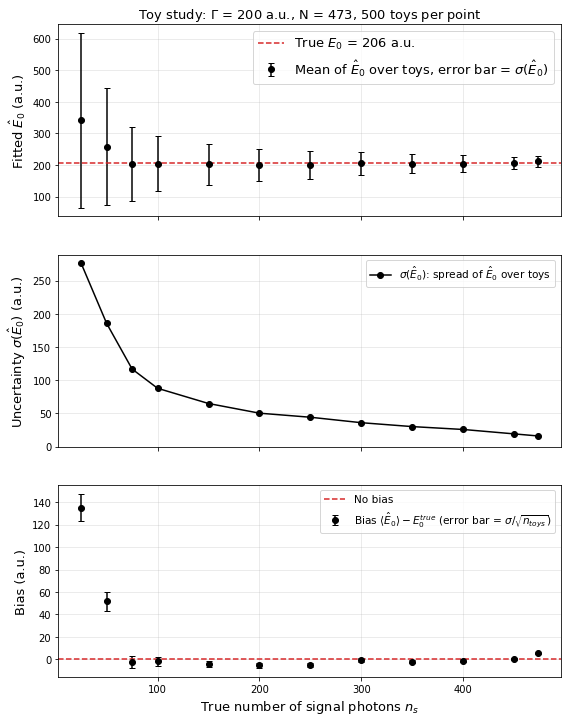

In [9]:
Gamma_true = 200.0 # fixed by the problem
E0_true = round(E0_hat)

n_toys = 500
ns_true_list = [25, 50, 75, 100, 150, 200, 250, 300, 350, 400, 450, 473]
rng = np.random.default_rng(42)

def simulate(ns):
    F0 = 0.5 + np.arctan((0.0 - E0_true) / Gamma_true)/np.pi
    u = rng.uniform(F0, 1.0, ns)
    E_sig = E0_true + Gamma_true * np.tan(np.pi * (u - 0.5))
    E_bkg = rng.exponential(E_b, N - ns)
    return np.concatenate([E_sig, E_bkg])

def m2lnL_toy(params, E_data):
    E0, ns = params
    norm = 0.5 + np.arctan(E0 / Gamma_true) / np.pi
    fs = 1.0 / (np.pi * Gamma_true * (1.0 + ((E_data - E0) / Gamma_true)**2)) / norm
    fB = np.exp(-E_data / E_b) / E_b
    f = (ns / N) * fs + ((N - ns)/ N) * fB
    return -2.0 * np.sum(np.log(np.maximum(f, 1e-3000)))

bounds_toy = [(0.0, 1000.0), (0.0, N)]
E0_starts = [50, 150, 250, 400, 600, 850] # several starts to find the global minimum

def fit_toy(E_data):
    best = None
    for E0_start in E0_starts:
        r = minimize(m2lnL_toy, [E0_start, N /2], args=(E_data,), method="L-BFGS-B", bounds=bounds_toy, options={"ftol":1e-14, "gtol":1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return best.x[0]

# Running the simulation
E0_fits = {}
for ns in ns_true_list:
    E0_fits[ns] = np.array([fit_toy(simulate(ns)) for _ in range(n_toys)])

ns_arr = np.array(ns_true_list)
E0_mean = np.array([E0_fits[ns].mean() for ns in ns_true_list])
E0_sigma = np.array([E0_fits[ns].std(ddof=1) for ns in ns_true_list])
E0_mean_err = E0_sigma / np.sqrt(n_toys)
bias = E0_mean - E0_true

print(f"{'ns_true':>7} {'mean E0_hat':>12} {'sigma(E0_hat)':>14} {'bias':>16}")
for ns, m, s, b, be in zip(ns_arr, E0_mean, E0_sigma, bias, E0_mean_err):
    print(f"{ns:7d} {m:12.1f} {s:14.1f} {b:+9.1f} $\pm$ {be:4.1f}")

# plots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9,12), sharex=True)

ax1.errorbar(ns_arr, E0_mean, yerr=E0_sigma, fmt="o", color="black", capsize=3, label=r"Mean of $\hat{E}_0$ over toys, error bar = $\sigma(\hat{E}_0)$")
ax1.axhline(E0_true, color="tab:red", ls="--", label=f"True $E_0$ = {E0_true} a.u.")
ax1.set_ylabel(r"Fitted $\hat{E}_0$ (a.u.)", fontsize=13)
ax1.set_title(rf"Toy study: $\Gamma$ = {Gamma_true:.0f} a.u., N = {N}, {n_toys} toys per point", fontsize=13)
ax1.legend(fontsize=13)
ax1.grid(alpha=0.3)

ax2.plot(ns_arr, E0_sigma, "o-", color="black", label=r"$\sigma(\hat{E}_0)$: spread of $\hat{E}_0$ over toys")
ax2.set_ylabel(r"Uncertainty $\sigma(\hat{E}_0)$ (a.u.)", fontsize=13)
ax2.set_ylim(bottom=0)
ax2.legend(fontsize=10.5)
ax2.grid(alpha=0.3)

ax3.errorbar(ns_arr, bias, yerr=E0_mean_err, fmt="o", color="black", capsize=3, label=r"Bias $\langle\hat{E}_0\rangle - E_0^{true}$ (error bar = $\sigma/\sqrt{n_{toys}}$)")
ax3.axhline(0, color="tab:red", ls="--", label="No bias")
ax3.set_xlabel(r"True number of signal photons $n_s$", fontsize=13)
ax3.set_ylabel("Bias (a.u.)", fontsize=13)
ax3.legend(fontsize=10.5)
ax3.grid(alpha=0.3)

From here, we can see that the estimator of $E_0$ is consistent, as the spreaad of the fitted $E_0$ shrinks steadily as the real value of $n_s$ grows from 276 a.u. at $n_s = 25$ to 16 a.u. at $n_s = 473$, which basically shows that more signal photons means a more precise $E_0$.

However, that doesn't mean that it's unbiased. For a small $n_s$ (25 and 50), the bias is actually rather large, ranging from +135 and +52 a.u. Without a lot of signal photons, the likelihood is quite flat, so many fits wander up to a high $E_0$.

For $n_s$ values ranging from 75 to 450, the bias is a few a.u., and that's at most about $10\%$ of the spread, and mostly within 2 error bars of zero.

For $n_s = 473$, there is a small, but a real bias of $+5.2 \pm 0.7$ a.u., as the fitted $n_s$ can't exceed $N$, so it can only miss on the low side. When it does, the fit treats some low-energy signal photons as background, which pushes the value of $E_0$ up.

Okay, now this is part 1 for the Chi-square fitting part of the project

Bin width = 16.0 a.u.
Photons in 0-400 a.u.: 466, above 400 a.u.: 7, total N = 473
Counters per bin: [56 39 25 23 19 21 17 14 20 15 22 29 50 37 20 21  9  7  4  6  5  2  1  2
  2]


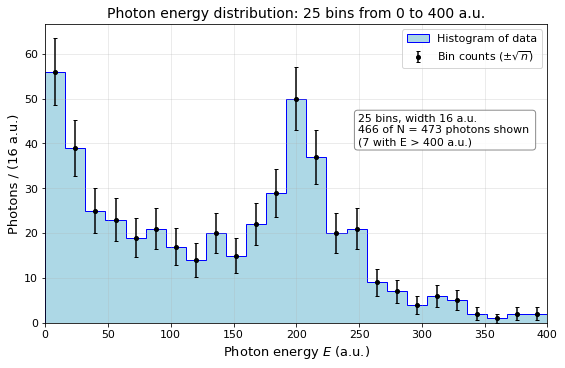

In [12]:
# This is for the 25 equal-width bins
n_bins = 25
E_lo, E_hi = 0.0, 400.0
bin_edges_chi = np.linspace(E_lo, E_hi, n_bins + 1) # 26 edges for 25 bins
bin_width_chi = bin_edges_chi[1] - bin_edges_chi[0] # 400/25 = 16 a.u.

counts_chi, _ = np.histogram(E, bins=bin_edges_chi)
centers_chi = 0.5 * (bin_edges_chi[:-1] + bin_edges_chi[1:])
errors_chi = np.sqrt(counts_chi) # this is for the Poisson uncertainty per bin

n_in = counts_chi.sum()
n_above = np.sum(E > E_hi)

print(f"Bin width = {bin_width_chi:.1f} a.u.")
print(f"Photons in 0-400 a.u.: {n_in}, above 400 a.u.: {n_above}, total N = {N}")
print("Counters per bin:", counts_chi)

fig, ax = plt.subplots(figsize=(9,5.5))
ax.hist(E, bins=bin_edges_chi, histtype="stepfilled", color="lightblue", edgecolor="blue", label="Histogram of data")
ax.errorbar(centers_chi, counts_chi, yerr=errors_chi, fmt="o", color="black", markersize=4, capsize=2, label=r"Bin counts ($\pm\sqrt{n}$)")
ax.text(0.97, 0.70, f"{n_bins} bins, width {bin_width_chi:.0f} a.u. \n"
                    f"{n_in} of N = {N} photons shown \n"
                    f"({n_above} with E > {E_hi:.0f} a.u.)",
                    transform=ax.transAxes, ha="right", va="top", multialignment="left",
                    fontsize=11,
                    bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))

ax.set_xlabel("Photon energy $E$ (a.u.)", fontsize=13)
ax.set_ylabel(f"Photons / ({bin_width_chi:.0f} a.u.)", fontsize=13)
ax.set_title(f"Photon energy distribution: {n_bins} bins from 0 to {E_hi:.0f} a.u.", fontsize=14)
ax.set_xlim(E_lo, E_hi)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=11)
ax.grid(alpha=0.3)
ax.legend(fontsize=11, loc="upper right")

From here, we see that there are 25 bins of 16 a.u. each, from 0 to 400 a.u., where 466/473 photons fall between 0 and 400 a.u., while the other 7 are above 400 a.u. and therefore outside of the histogram.

From here, we can also see that the highest-energy bins have very few photon counts, and there are the $\sqrt{n}$ errors which are poor estimates, and a chi-square fit is usually less reliable than the likelihood fit. 

Now, this is part 2

In [13]:
from scipy.stats import chi2 as chi2_dist

# cumulative distribution functions: the integral of each pdf from -infinity up to x
def lorentz_cdf(x, E0, Gamma):
    return 0.5 + np.arctan((x - E0) / Gamma) / np.pi

def expo_cdf(x):
    return 1.0 - np.exp(-x / E_b)

def expected_counts(params):
    E0, Gamma, ns = params
    nb = N - ns
    lo, hi = bin_edges_chi[:-1], bin_edges_chi[1:]
    mu_s = ns * (lorentz_cdf(hi, E0, Gamma) - lorentz_cdf(lo, E0, Gamma))
    mu_b = nb * (expo_cdf(hi) - expo_cdf(lo))
    return mu_s + mu_b

def chi2(params):
    mu = expected_counts(params)
    return np.sum((counts_chi - mu)**2 / errors_chi**2)

p0_chi = [200.0, 25.0, 190.0]
bounds_chi = [(0.0, 400.0), (1e-3, 200.0), (0.0, N)]

res_chi = minimize(chi2, p0_chi, method="L-BFGS-B", bounds=bounds_chi)

E0_chi, Gamma_chi, ns_chi = res_chi.x
nb_chi = N - ns_chi
chi2_min = res_chi.fun
n_params = len(res_chi.x)
ndof = n_bins - n_params

print("Converged:", res_chi.success, "-", res_chi.message)
print(f"E0 = {E0_chi:.2f} a.u.")
print(f"Gamma = {Gamma_chi:.2f} a.u.")
print(f"ns = {ns_chi:.1f}")
print(f"nb = {nb_chi:.1f}")
print(f"chi2_min = {chi2_min:.2f}")
print(f"Degrees of freedon = {n_bins} bins - {n_params} fitted parameters = {ndof}")
print(f"chi2/ndof = {chi2_min / ndof:.2f}, p-value = {chi2_dist.sf(chi2_min, ndof):.3f}")

Converged: True - CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
E0 = 204.51 a.u.
Gamma = 23.32 a.u.
ns = 197.1
nb = 275.9
chi2_min = 15.27
Degrees of freedon = 25 bins - 3 fitted parameters = 22
chi2/ndof = 0.69, p-value = 0.851


What this all does is that it minimizes

$\begin{equation}
    \chi^2 (E_0, \Gamma, n_s) = \sum_{i=1}^{25} \frac{(n_i - \mu_i)^2}{\sigma_i^2}, \quad \quad \sigma_i = \sqrt{n_i} \notag
\end{equation}$

where $n_i$ is the observed count in bin $i$, and $\mu_i$ is the count the model predicts

$\begin{equation}
    \mu_i = n_s \int_{\text{bin } i} f_s(E) dE + n_b \int_{\text{bin } i} f_B (E) dE, \quad \quad n_b = N - n_s \notag
\end{equation}$

See, the model is integrated over each bin, not evalauted at its center. The bins are 16 a.u. wide and the peak is only around 22 a.u. wide, so the pdf changes a lot across just one bin. The integrals are computed exactly from the CDFs.

Additionally, the model is scaled to all $N = 473$ photons, so each pdf is normalized over all energies, so the model automatically predicts that some photons will land above 400 a.u. (7 observed).

Now this is part 3, which is the calculating of the p-value for the minimized chi-squared

In [14]:
# p-value = probability of a chi2 at least this large if the model is actually correct
p_value = chi2_dist.sf(chi2_min, ndof) # where sf = 1 - cdf

print(f"chi2_min = {chi2_min:.2f}")
print(f"ndof = {ndof}")
print(f"chi2_min / ndof = {chi2_min / ndof:.2f}")
print(f"p-value = {p_value:.3f}")

chi2_min = 15.27
ndof = 22
chi2_min / ndof = 0.69
p-value = 0.851


Since p = 0.851, if the model is actually correct, then $85\%$ of repeated experiments would give a chi-square value worse than 0.851. In general, this is actually pretty good because the scatter looks like normal random fluctuations.

If the model were wrong, the graph would look QUITE extreme, and we would probably be able to eye-ball the fact that it is wrong. There is also a reasonable amount of error that it doesn't look suspicious from the get-go.

Now, onto part 4.

No, the binned chi-square method isn't the best method, because it relies on large counters per bin, and with 473 photons, a lot of the high-energy region has only 1-9 photons per bin, so the $\sqrt{n}$ errors are poor, and some of the bins could be empty.

Unbinned maximum likelihood uses each photon directly and works for $n$ sample size, so naturally it's the better method.

I would trust the conclusions of the p-value, but not its exact value. The formula $p = P(\chi^2_{22} \geq 15.27)$ assumes that a ci-square distribution, which is only true for large counts. The simulation showed that the actual distributio is about $70\%$ wider than assumed, so the chi-square sits in the middle of that distribution, where the error is quite small.